# GPT-2 small activation atlas: a demo

Five steps through what works today, each running in seconds on a laptop: one neuron over 1M tokens of OpenWebText;
one token followed into the SAE basis; the features checked against Neuronpedia; the IOI circuit's self-repair on one
prompt, in the features; and what the SAEs miss. The full analyses, with errors and systematics, are in
`docs/results-stage1.md` and `docs/results-stage2.md`; this notebook only shows the machinery.

It reads the default atlas (`run-atlas` → `results/atlas`) and the SAE atlas (`results/atlas-sae`, the `--sae` run in the
README), and fetches feature dashboards from Neuronpedia's public API once, caching them under `results/neuronpedia/`.

    source setup.sh && jupyter lab notebooks/demo.ipynb      # or headless: run-notebook notebooks/demo.ipynb

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import torch

import atlas
import ioi
from atlas import HFGPT2, load_tokenizer
from sae_gate import load_sae, neuronpedia_features, patch_resid_pre, sae_id_for

ATLAS, SAE_ATLAS, NP = Path("../results/atlas"), Path("../results/atlas-sae"), Path("../results/neuronpedia")
q = lambda s: duckdb.sql(s).show(max_width=160)
tok = load_tokenizer()

/Users/ryan/Development/gpt2-atlas/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. One neuron over 1M tokens

The atlas is plain Parquet: per-unit statistics in `neurons.parquet`, the 20 strongest contexts of every unit in
`topk.parquet`. Which MLP neurons have the most top contexts on the token " John"?

In [2]:
q(f"""select layer, unit, count(*) as n from '{ATLAS}/topk.parquet'
      where kind = 'post' and token = ' John' group by all order by n desc, layer, unit limit 5""")

┌───────┬───────┬───────┐
│ layer │ unit  │   n   │
│ int64 │ int64 │ int64 │
├───────┼───────┼───────┤
│     6 │  1282 │    14 │
│     3 │  1448 │     8 │
│     8 │   267 │     6 │
│    10 │  2731 │     6 │
│    11 │  1274 │     5 │
└───────┴───────┴───────┘



`atlas show` (here as a function; on the command line, `python -m atlas show results/atlas post 6 1282`) prints a
unit's statistics and its top contexts. The atlas stores only `(row, pos)` pointers, so each context is rerun from
`tokens.npy` through the model: that shows the unit on every token around the stored one, and checks that the stored
value comes back.

In [3]:
atlas.show(ATLAS, "post", 6, 1282, k=6);

blocks.6.mlp.hook_post, unit 1282, in ../results/atlas (992,632 tokens)
  mean -0.0765 ± 9.4e-05, std 0.143, max 3.67, positive on 5.35% of tokens, p99 0.563, p99.9 1.58


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 25089.20it/s]

top 6 contexts, rerun from tokens.npy (stored → recomputed; ⟨⟩ marks tokens at least a quarter as far from the unit's mean as the marked one):
  #0  row 1386, pos 125: 3.667 → 3.667   The outcome of the court case is anyone’s guess, with Chief Justice« John»⟨3.67⟩ Roberts and
  #1  row 3937, pos 96: 3.610 → 3.610    fear of a backlash against Muslims that never comes.⏎⏎The protesters are correct⟨2.56⟩« in»⟨3.61⟩ exactly⟨1.37⟩ one sense:
  #2  row 6836, pos 111: 3.489 → 3.489    since George W. Bush's picks of Samuel Alito in 2006 and Chief Justice« John»⟨3.49⟩ Roberts in 2005.
  #3  row 332, pos 20: 3.221 → 3.221    2015⏎⏎Sovereign Valley Farm, Chile⏎⏎The government committee was« clear»⟨3.22⟩—if nothing was
  #4  row 5554, pos 12: 3.214 → 3.214   e.⏎⏎WASHINGTON - U.S. Representative« John»⟨3.21⟩ Lewis (GA-
  #5  row 2194, pos 14: 3.179 → 3.179   Content originally published at iBankCoin.com⏎⏎Congressman« John»⟨3.18⟩ Conyers - who
  worst relative difference, stored vs recomputed: 1.1e

Neuron L6/1282 fires hardest on " John" after a title (Chief Justice John Roberts, Representative John Lewis,
Congressman John Conyers), and also on unrelated words (" in", " clear"). A neuron mixes several things; sparse
autoencoder features are meant to separate them.

## 2. One token, in the SAE basis

The SAE atlas encodes the same tokens with Joseph Bloom's residual SAEs (24,576 features per layer) and keeps every
nonzero feature activation at layer 9 as a sparse event. Take the neuron's top context, row 1386, position 125, and
ask which layer-9 features are active there, with each feature's firing rate over the 1M tokens:

In [4]:
row, pos = 1386, 125
tokens = np.load(SAE_ATLAS / "tokens.npy", mmap_mode="r")
print(repr(tok.decode(tokens[row, pos - 10 : pos + 1])))
feats = duckdb.sql(f"""select e.feature, e.value, n.frac_pos as rate
      from '{SAE_ATLAS}/events-L9-*.parquet' e join '{SAE_ATLAS}/neurons.parquet' n
        on n.kind = 'sae' and n.layer = 9 and n.unit = e.feature
      where e.row = {row} and e.pos = {pos} order by e.value desc limit 6""").df()
print(feats.round(4).to_string(index=False))

' is anyone’s guess, with Chief Justice John'
 feature   value   rate
   15470 51.3797 0.0002
   18435 14.5188 0.0054
    8979 14.0748 0.0002
   21361 12.8156 0.0018
   17752  8.8254 0.0051
   23830  8.6204 0.0009


The strongest feature fires on 0.02% of tokens, against 5% for the neuron, and its top contexts are all " John" in
one name, Speaker John Boehner. Rerun the same way:

In [5]:
atlas.show(SAE_ATLAS, "sae", 9, int(feats.feature[0]), k=5);

blocks.9.hook_resid_pre.sae, unit 15470, in ../results/atlas-sae (992,632 tokens)
  mean 0.00345 ± 0.0004, std 0.373, max 71.1, positive on 0.02% of tokens, p99 -1.11e-05, p99.9 -8.98e-07


/Users/ryan/Development/gpt2-atlas/.venv/lib/python3.13/site-packages/sae_lens/saes/sae.py:256: UserWarning: 
This SAE has non-empty model_from_pretrained_kwargs. 
For optimal performance, load the model like so:
model = HookedSAETransformer.from_pretrained_no_processing(..., **cfg.model_from_pretrained_kwargs)
  warnings.warn(


  SAE: gpt2-small-res-jb


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 22326.18it/s]

top 5 contexts, rerun from tokens.npy (stored → recomputed; ⟨⟩ marks tokens at least a quarter as far from the unit's mean as the marked one):
  #0  row 2204, pos 104: 71.077 → 71.077   . Toomey (Pa.).⏎⏎A similar ad will target House Speaker« John»⟨71.08⟩ A. Boehner (
  #1  row 4120, pos 108: 68.681 → 68.681    the House, at least, the immediate goal of the letter is to prompt Speaker« John»⟨68.68⟩ A. Boehner (
  #2  row 4938, pos 27: 68.312 → 68.312    Breitbart News there are at least 17 GOP members who plan to unseat House Speaker« John»⟨68.31⟩ Boehner on Thursday,
  #3  row 4398, pos 59: 67.204 → 67.204    Congress -- loathe Obamacare.⏎⏎Remember back a few weeks ago when Speaker« John»⟨67.20⟩ Boehner and Majority Leader
  #4  row 1257, pos 49: 65.603 → 65.603    to others who may try to enter the US illegally. The Republican House speaker,« John»⟨65.60⟩ Boehner, has said
  worst relative difference, stored vs recomputed: 7.8e-07


## 3. Checked against Neuronpedia

Neuronpedia hosts dashboards for these SAEs: an automatic explanation and the tokens each feature's decoder direction
boosts most ("top logits"). The atlas's gate (`docs/results-stage2.md` §1–2) checks that our features match them.

In [6]:
np_feats = neuronpedia_features("9-res-jb", feats.feature.tolist(), NP)
for f in feats.feature:
    d = np_feats[int(f)]
    expl = (d.get("explanations") or [{}])[0].get("description", "")
    print(f"{f:6d}  {expl[:60]:60s}  top logits: {', '.join(repr(t) for t in d.get('pos_str', [])[:4])}")
    print(f"        https://www.neuronpedia.org/gpt2-small/9-res-jb/{f}")

 15470  the name "John" mentioned in the text                         top logits: 'athan', 'nie', ' Doe', ' Hancock'
        https://www.neuronpedia.org/gpt2-small/9-res-jb/15470
 18435  legal terms and references to court cases                     top logits: ' Scalia', ' justices', ' upholding', ' appellate'
        https://www.neuronpedia.org/gpt2-small/9-res-jb/18435
  8979  names, specifically the name "John."                          top logits: 'athan', ' Doe', 'nie', 'ston'
        https://www.neuronpedia.org/gpt2-small/9-res-jb/8979
 21361  terms related to government officials, particularly those wi  top logits: ' Mattis', ' Spicer', ' Flynn', ' Tillerson'
        https://www.neuronpedia.org/gpt2-small/9-res-jb/21361
 17752  mentions of legal judges and their decisions                  top logits: ' rulings', ' verdict', ' jurisdiction', 'jud'
        https://www.neuronpedia.org/gpt2-small/9-res-jb/17752
 23830  names of legal figures, particularly Supreme Court justices   to

The neuron's two meanings come apart: features for the name John, and a separate feature for courts and justices.

## 4. The IOI circuit's self-repair, in features

In "Then, John and Sarah went to the office. Sarah gave a book to", GPT-2 small predicts " John" (the indirect object,
IO) over " Sarah" (the subject, S). The logit difference LD = logit(IO) − logit(S) is carried by name-mover heads
{9.9, 9.6, 10.0}. Mean-ablating them, as in [ioi-hydra](https://github.com/rreece/ioi-hydra), removes their direct
effect, yet the LD barely moves: other heads repair it. Which SAE features carry the LD at the final residual stream,
before and after the repair? At the final residual the LD splits exactly into features, the SAE's bias and its error.

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 20057.42it/s]

/Users/ryan/Development/gpt2-atlas/.venv/lib/python3.13/site-packages/sae_lens/saes/sae.py:256: UserWarning: 
This SAE has non-empty model_from_pretrained_kwargs. 
For optimal performance, load the model like so:
model = HookedSAETransformer.from_pretrained_no_processing(..., **cfg.model_from_pretrained_kwargs)
  warnings.warn(


LD clean 4.03, name movers ablated 5.77; their direct effect lost: 3.55
  clean    features  4.32 + bias  0.64 + SAE error -2.45
  ablated  features  4.60 + bias  0.67 + SAE error -1.02



feature   LD clean → ablated   top logits on Neuronpedia
   9680    +4.49 →  +4.80    'John', ' John', 'john', ' JOHN'
   5741    +0.19 →  +0.25    ' herself', ' her', ' husband', ' boyfriend'
  18623    +0.18 →  +0.16    ' Jesus', 'Jesus', ' Galile', ' crucifix'
  24393    -0.12 →  -0.11    ' downstairs', ' upstairs', ' bed', 'stairs'
   1926    -0.14 →  -0.11    ' glances', ' clenched', ' her', ' hers'


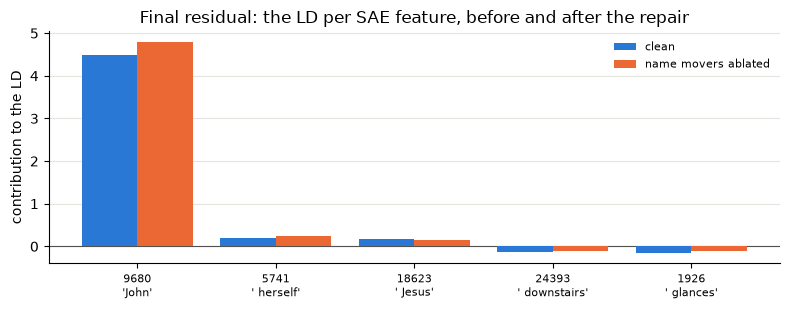

In [7]:
hf = HFGPT2("cpu")
ds = ioi.make_ioi_dataset(tok)
i = ds.prompts.index("Then, John and Sarah went to the office. Sarah gave a book to")
clean = ioi.run(hf, ds)
with ioi.ablate_heads(hf, ioi.NAME_MOVERS, ioi.ablation_reference(hf, ds, "mean")):
    ablated = ioi.run(hf, ds)
sae12 = load_sae("gpt2-small-res-jb", sae_id_for("gpt2-small-res-jb", 12), "cpu")

def split(r):
    x = r["resid"][12][i : i + 1]
    return ioi.feature_attribution(sae12, x, r["d"][i : i + 1], (x.pow(2).mean(-1) + hf.model.ln_f.eps).sqrt())

fc, fa = split(clean), split(ablated)
lost = sum(clean["de"][i, l, h] - ablated["de"][i, l, h] for l, h in ioi.NAME_MOVERS)
print(f"LD clean {clean['ld'][i]:.2f}, name movers ablated {ablated['ld'][i]:.2f}; their direct effect lost: {lost:.2f}")
for name, f in (("clean", fc), ("ablated", fa)):
    print(f"  {name:8s} features {f['contrib'].sum():5.2f} + bias {f['bias'].item():5.2f} + SAE error {f['error'].item():5.2f}")
top = sorted(set(fc["contrib"][0].abs().topk(5).indices.tolist()) | set(fa["contrib"][0].abs().topk(5).indices.tolist()),
             key=lambda f: -float(fc["contrib"][0, f] + fa["contrib"][0, f]))
np12 = neuronpedia_features("12-res-jb", top, NP)
print("\nfeature   LD clean → ablated   top logits on Neuronpedia")
for f in top:
    print(f"{f:7d}   {fc['contrib'][0, f]:+6.2f} → {fa['contrib'][0, f]:+6.2f}    {', '.join(repr(t) for t in np12[f].get('pos_str', [])[:4])}")

fig, ax = plt.subplots(figsize=(8, 3.2))
xs = np.arange(len(top))
ax.bar(xs - 0.2, fc["contrib"][0, top], 0.4, label="clean", color="#2a78d6", zorder=3)
ax.bar(xs + 0.2, fa["contrib"][0, top], 0.4, label="name movers ablated", color="#eb6834", zorder=3)
ax.set_xticks(xs, [f"{f}\n{np12[f].get('pos_str', ['?'])[0]!r}" for f in top], fontsize=8)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set(ylabel="contribution to the LD", title="Final residual: the LD per SAE feature, before and after the repair")
ax.grid(axis="y", color="#e5e4df", zorder=0)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

The repair restores the clean representation. On this prompt one feature, 9680, whose decoder direction boosts
"John" above every other token, carries the LD clean (+4.49) and with the name movers ablated (+4.80): the backup heads
and the released brake (10.7) write the same "say John" feature the name movers did. Here the repair even overshoots
(LD 4.03 → 5.77). Over all 128 prompts the per-feature LD contributions after the repair match the clean run's at
cosine 0.92 (`docs/results-stage2.md` §3).

## 5. What the SAEs miss

On this prompt the SAE's features overshoot the LD and its error is negative, but over the 128 prompts the error
carries about half the LD for Bloom's dictionary: small in norm, but along the logit direction. Splicing an SAE's
reconstruction into the stream before layer 10 shows the cost directly. Apollo's end-to-end SAE, trained on the
model's output rather than on reconstruction, keeps more of the LD than a local SAE at about the same sparsity. Both
were trained without a BOS, so the prompts here drop it:

In [8]:
nb = ioi.drop_bos(ds)

def spliced_ld(sae=None):
    fn = (lambda x: sae.decode(sae.encode(x))) if sae is not None else (lambda x: None)
    h = patch_resid_pre(hf.model.h[10], fn)
    try:
        return ioi.run(hf, nb, resid_layers=(12,))["ld"]
    finally:
        h.remove()

base = spliced_ld()
print(f"no SAE: LD {base[i]:.2f} on this prompt, {base.mean():.2f} on average over the 128 prompts")
for label, rel in (("Apollo local SAE (L0 ~73)", "gpt2-small-res_sll-ajt"), ("Apollo end-to-end SAE (L0 ~66)", "gpt2-small-res_sle-ajt")):
    ld = spliced_ld(load_sae(rel, "blocks.10.hook_resid_pre", "cpu"))
    print(f"{label:32s} LD {ld[i]:.2f} on this prompt; keeps {ld.mean() / base.mean():.0%} on average")

no SAE: LD 4.18 on this prompt, 3.03 on average over the 128 prompts


Apollo local SAE (L0 ~73)        LD 0.42 on this prompt; keeps 50% on average


Apollo end-to-end SAE (L0 ~66)   LD 2.43 on this prompt; keeps 68% on average


Every SAE loses part of the answer, and the end-to-end objective loses less. Whether an objective weighted to the task
would recover the rest is the open question for stage 3 (`docs/atlas-design.md`, Roadmap).